# 2026년 9월 PCE release research

발표값·수정값·최근 물가 속도를 구분하고 실질 소비와 연결한다. 기준일 2026-10-29. 미래 수익률 예측 모형이나 백테스트는 포함하지 않는다.

저장 출력은 각 코드 셀을 순서대로 CPython으로 실제 실행해 생성했다. 이 환경에는 Jupyter 커널이 없어 커널에서의 재실행은 검증하지 않았다. 코드는 매직 명령 없이 일반 Python으로 작성했다.

In [1]:
from pathlib import Path
import base64, json, sqlite3, subprocess, sys
import pandas as pd
ROOT = Path.cwd()
assert (ROOT / "run_analysis.py").is_file(), "프로젝트 루트에서 실행하세요."
def show_png(path):
    payload = Path(path).read_bytes()
    try:
        from IPython.display import display, Image
    except ModuleNotFoundError:
        return {"image/png": base64.b64encode(payload).decode()}
    display(Image(data=payload))
print("Research root verified. No account credentials required.")


Research root verified. No account credentials required.


## 1. 원자료 해시와 전체 분석 재실행

고정된 자료를 사용한다. 수집 실패나 값 불일치를 가짜 값·이전 자료의 최신 표시로 대체하지 않는다.

In [2]:
result = subprocess.run([sys.executable, str(ROOT / "run_analysis.py")], cwd=ROOT, capture_output=True, text=True, check=True)
print(result.stdout)
if result.stderr:
    print(result.stderr)


{
  "reference_period": "2026-09",
  "release_at_kst": "2026-10-29T21:30:00+09:00",
  "data_vintage": "retrieved 2026-10-29, revised historical series; not real-time historical vintage",
  "headline_mom_pct": 0.4908404312709447,
  "headline_yoy_pct": 3.648874225123633,
  "core_mom_pct": 0.31650177409587865,
  "core_yoy_pct": 3.1211596029620203,
  "core_3m_annualized_pct": 2.9025218811834064,
  "core_6m_annualized_pct": 2.92269972199517,
  "real_pce_mom_pct": 0.01531664212075512,
  "real_dpi_mom_pct": -0.27204309249466707,
  "saving_rate_pct": 3.8,
  "latest_common_yields": {
    "date": "2026-10-27",
    "nominal_2y": 4.7,
    "nominal_10y": 4.99,
    "real_10y": 2.64,
    "breakeven_10y": 2.35
  },
  "discounting_20y_change_pct": -16.83412695859542,
  "scope": "Descriptive release analysis, momentum transforms and illustrative discounting. No return prediction model, causal estimate, OOS investment result or backtest.",
  "n_monthly_dates": 153,
  "n_feature_rows": 705,
  "n_daily_dat

## 2. SQL로 최신 결과 추출

물가·실질 지출의 수준 계열에는 변화율을, 저축률에는 퍼센트포인트 차이를 사용한다.

In [3]:
with sqlite3.connect(ROOT / "outputs/research.sqlite") as con:
    con.create_function("POWER", 2, lambda x,y: None if x is None or y is None else x**y)
    latest = pd.read_sql_query("SELECT * FROM monthly_changes WHERE date='2026-09-01' ORDER BY series_id", con)
    revisions = pd.read_sql_query("SELECT * FROM revision_comparison", con)
print(latest.to_string(index=False))
print("\nPublication-vintage comparison:")
print(revisions.to_string(index=False))


      date series_id     value   mom_pct  yoy_pct  annualized_3m_pct  annualized_6m_pct  mom_change_pp
2026-09-01   DSPIC96 18366.100 -0.272043 0.953130           0.167876           0.706098            NaN
2026-09-01    PCEC96 16977.600  0.015317 2.536600           2.965855           3.671020            NaN
2026-09-01     PCEPI   132.257  0.490840 3.648874           3.558178           3.335456            NaN
2026-09-01  PCEPILFE   130.902  0.316502 3.121160           2.902522           2.922700            NaN
2026-09-01   PSAVERT     3.800       NaN      NaN                NaN                NaN           -0.2

Publication-vintage comparison:
      metric  period    unit  first_value  revised_value  revision_pp
core_pce_mom 2026-08 percent          0.2            0.3          0.1
real_pce_mom 2026-08 percent          0.6            0.5         -0.1
 saving_rate 2026-08 percent          4.1            4.0         -0.1


## 3. 최근 3개월 연율 독립 계산

3개월 변화가 1년간 반복된다는 환산이다. 미래 물가 예측과 구분한다.

June index=129.969, September index=130.902, 3-month annualized=2.9025%


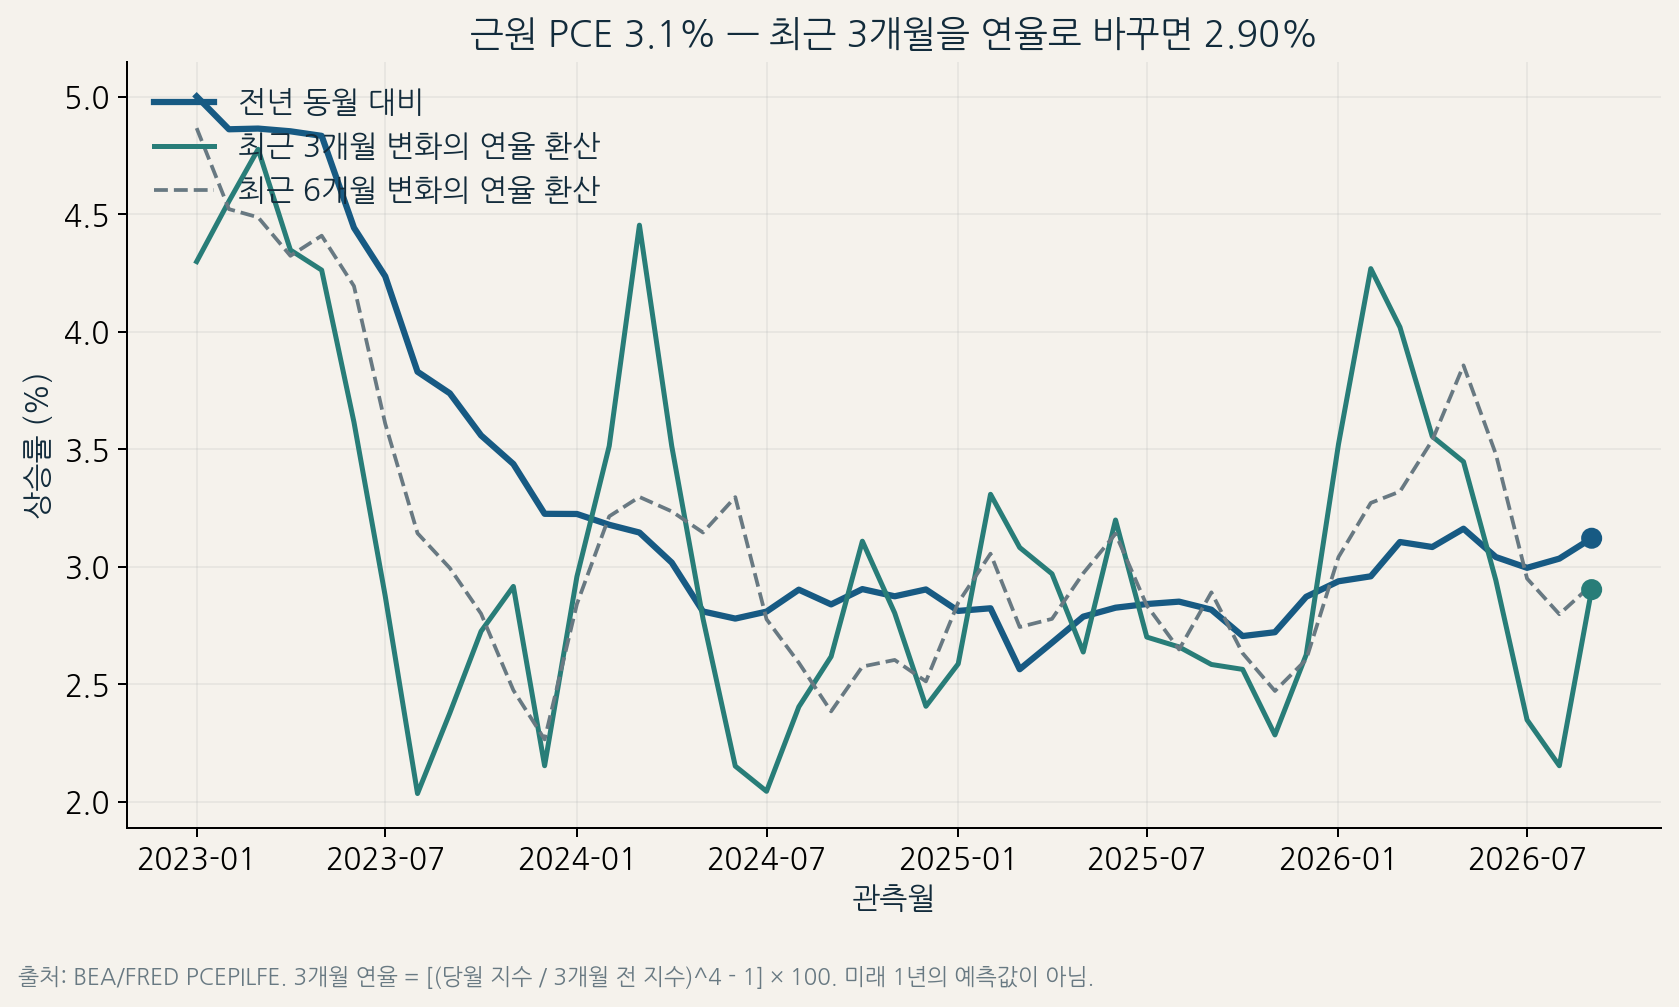

In [4]:
levels = pd.read_csv(ROOT / "outputs/monthly_levels.csv").set_index("date")
jun = levels.loc["2026-06-01", "PCEPILFE"]
sep = levels.loc["2026-09-01", "PCEPILFE"]
annualized = ((sep/jun)**4 - 1) * 100
recorded = json.loads((ROOT/"outputs/findings.json").read_text())["core_3m_annualized_pct"]
assert abs(annualized-recorded) < 1e-10
print(f"June index={jun:.3f}, September index={sep:.3f}, 3-month annualized={annualized:.4f}%")
show_png(ROOT / "figures/02_core_momentum.png")


## 4. 할인율 민감도와 해석

같은 미래 현금흐름을 가정한 설명용 계산이다. 실제 기업 주가 하락률 추정이 아니다.

 years  future_cash_flow  discount_base  discount_stress  pv_at_8pct  pv_at_9pct  change_pct
     5               100           0.08             0.09   68.058320   64.993139   -4.503757
    10               100           0.08             0.09   46.319349   42.241081   -8.804675
    20               100           0.08             0.09   21.454821   17.843089  -16.834127


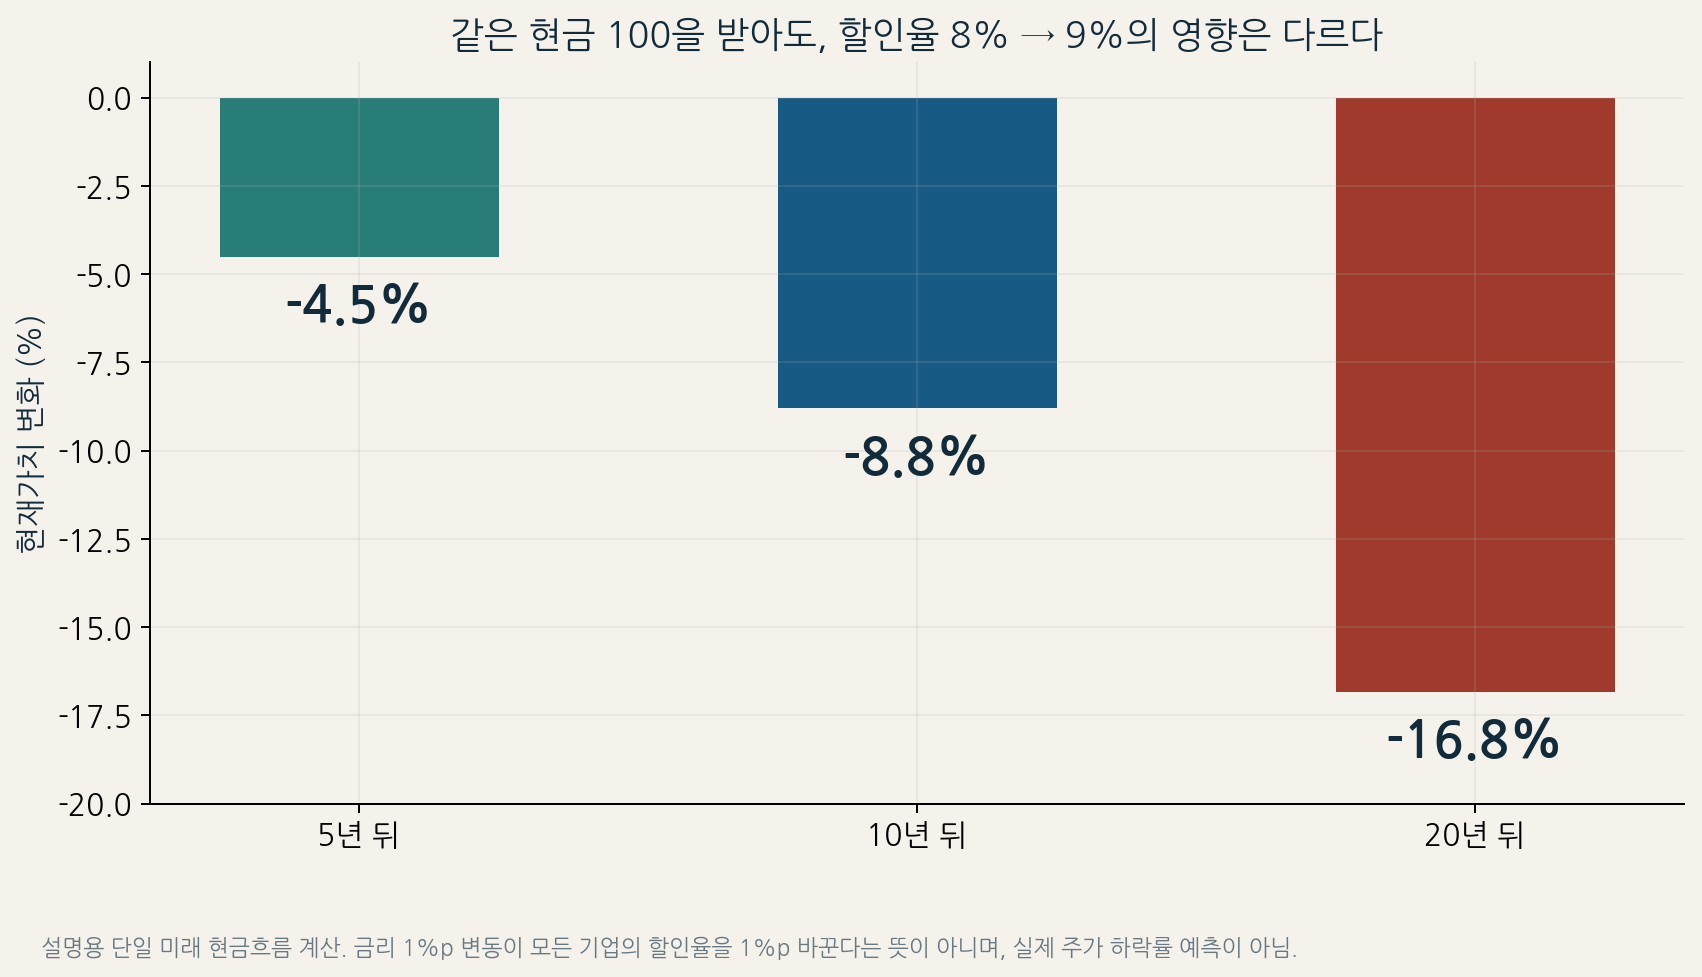

In [5]:
sensitivity = pd.read_csv(ROOT/"outputs/illustrative_discounting.csv")
print(sensitivity.to_string(index=False))
show_png(ROOT/"figures/05_discount_sensitivity.png")


## 5. 검증 결과와 분석 한계

최신 수정계열은 당시 이용 가능 자료와 다를 수 있다. 실시간 예측 성과를 주장하지 않는다. 표본·시점이 다른 선거 조사와 PCE 사이의 인과효과도 계산하지 않았다.

In [6]:
qa = json.loads((ROOT/"outputs/qa_results.json").read_text())
assert qa["passed"]
print(f"Passed {len(qa['checks'])} data checks.")
print("Actual/paper trades: none. Price forecast/backtest: none. Blog and social publication are tracked separately.")


Passed 39 data checks.
Actual/paper trades: none. Price forecast/backtest: none. Blog and social publication are tracked separately.
